# ECLYPSE+NET vs ns-3: analysis of the comparison

This notebook analyses the results of `main.py`, which simulates every scenario with
ECLYPSE+NET and with ns-3: the same network, the same packets (same IDs, sources,
destinations, sizes and sending times) and the same paths. The scenarios vary:

- **topology**: Internet AS graph, Barabási–Albert and Erdős–Rényi;
- **network size**: the number of routers;
- **step duration** of ECLYPSE+NET: 10, 1 and 0.1 ms;
- **load**: packets per second, split among the flows.

Processing times are zero in both simulators. What remains different is the model of
time: ns-3 forwards a packet as soon as it reaches a router, while ECLYPSE+NET moves
packets at the start of every step, so a packet that reaches a router waits for the
next step. Each hop after the first can therefore add up to one step duration to the
latency of a packet.

`main.py` saves one row per trial in `results.csv` and the packet-by-packet comparison
of each trial in `trials/<trial>/comparison.csv`, by default in
`~/eclypse-sim/ns3_comparison/`. Unless stated otherwise, charts show the mean over
topologies, sizes and seeds.

## Setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path(os.environ.get(
    "NS3_COMPARISON_RESULTS", Path.home() / "eclypse-sim" / "ns3_comparison"
))
df = pd.read_csv(RESULTS / "results.csv")

TOPOLOGIES = {
    "internet_as": "Internet AS graph",
    "scale_free": "Barabási–Albert",
    "random": "Erdős–Rényi",
}
TOPOLOGIES = {t: label for t, label in TOPOLOGIES.items() if t in set(df["topology"])}
STEPS = sorted(df["step_duration_s"].unique(), reverse=True)
LOADS = sorted(int(x) for x in df["packets_per_s"].unique())
SIZES = sorted(int(s) for s in df["routers"].unique())
STEP_COLORS = dict(zip(STEPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
NS3_COLOR = "#0b0b0b"


def step_label(dt):
    return f"{dt * 1000:g} ms"


def load_label(load):
    return f"{load:,} packets/s"


df["eclypse_drop_ratio"] = df["eclypse_dropped"] / df["sent"]
df["ns3_drop_ratio"] = df["ns3_dropped"] / df["sent"]

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})

print(f"{len(df)} trials; topologies {list(TOPOLOGIES)}, routers {SIZES}, "
      f"step durations {[step_label(s) for s in STEPS]}, loads {LOADS}")

72 trials; topologies ['internet_as', 'scale_free', 'random'], routers [16, 32, 64, 128], step durations ['10 ms', '1 ms', '0.1 ms'], loads [20000, 200000]


## 1. The same packets in both simulators

Every trial sends the same packets in both simulators. A packet is either delivered,
dropped because a queue is full, or, in ECLYPSE+NET only, still in transit when the
simulation ends (the simulation lasts long enough for this to be zero). The table
gives the totals over all the trials of each step duration and load.

In [2]:
totals = df.groupby(["packets_per_s", "step_duration_s"])[
    ["sent", "eclypse_delivered", "ns3_delivered", "eclypse_dropped", "ns3_dropped",
     "eclypse_in_transit_at_end", "both_delivered"]
].sum().sort_index(ascending=[True, False])
totals.index = totals.index.set_levels(
    [[load_label(x) for x in totals.index.levels[0]],
     [step_label(x) for x in totals.index.levels[1]]]
)
print(totals.to_string())

                                     sent  eclypse_delivered  ns3_delivered  eclypse_dropped  ns3_dropped  eclypse_in_transit_at_end  both_delivered
packets_per_s     step_duration_s                                                                                                                   
20,000 packets/s  10 ms             24252              24230          24252               22            0                          0           24230
                  1 ms              23748              23748          23748                0            0                          0           23748
                  0.1 ms            25272              25272          25272                0            0                          0           25272
200,000 packets/s 10 ms            241944             102179         141323           139765       100621                          0          101400
                  1 ms             241356             183831         183926            57525        57430 

Share of the packets dropped by each simulator, against the step duration. ns-3 also
depends on the step duration, because the packets of a step are sent at the same
instant: longer steps mean larger bursts. ECLYPSE+NET drops more when steps are long,
because all the packets that reach a router within a step are offered to its queues
at the same time, at the start of the next step.

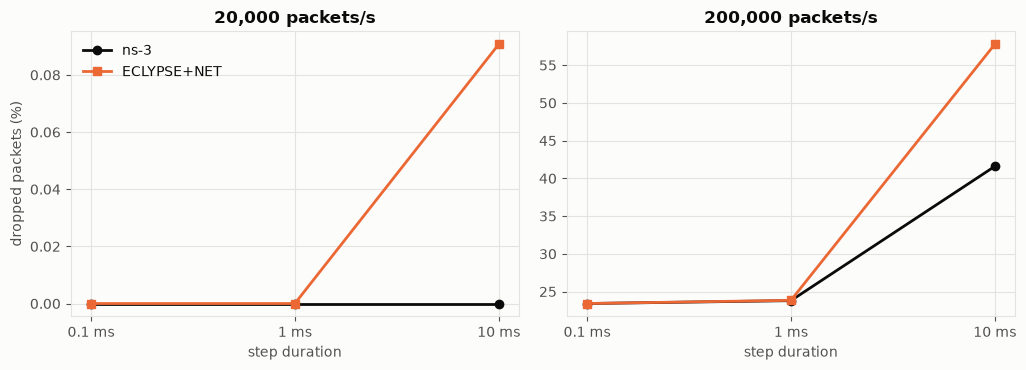

In [3]:
fig, axes = plt.subplots(1, len(LOADS), figsize=(5.2 * len(LOADS), 3.8), squeeze=False)
for ax, load in zip(axes[0], LOADS):
    d = df[df["packets_per_s"] == load].groupby("step_duration_s")[
        ["eclypse_drop_ratio", "ns3_drop_ratio"]].mean()
    ax.plot(d.index * 1000, d["ns3_drop_ratio"] * 100, color=NS3_COLOR, marker="o",
            linewidth=2, label="ns-3")
    ax.plot(d.index * 1000, d["eclypse_drop_ratio"] * 100, color="#eb6834",
            marker="s", linewidth=2, label="ECLYPSE+NET")
    ax.set_xscale("log")
    ax.set_xticks([s * 1000 for s in STEPS], [step_label(s) for s in STEPS])
    ax.minorticks_off()
    ax.set_xlabel("step duration")
    ax.set_title(load_label(load))
axes[0, 0].set_ylabel("dropped packets (%)")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
plt.show()

## 2. End-to-end latency

Left: mean end-to-end latency of the delivered packets in the two simulators. Right:
mean absolute difference between the latency of the same packet in the two
simulators, on the packets delivered by both, on log-log axes. The dashed line is
`(mean hops − 1) × step duration`: the delay that ECLYPSE+NET adds when a packet
waits a whole step at every router.

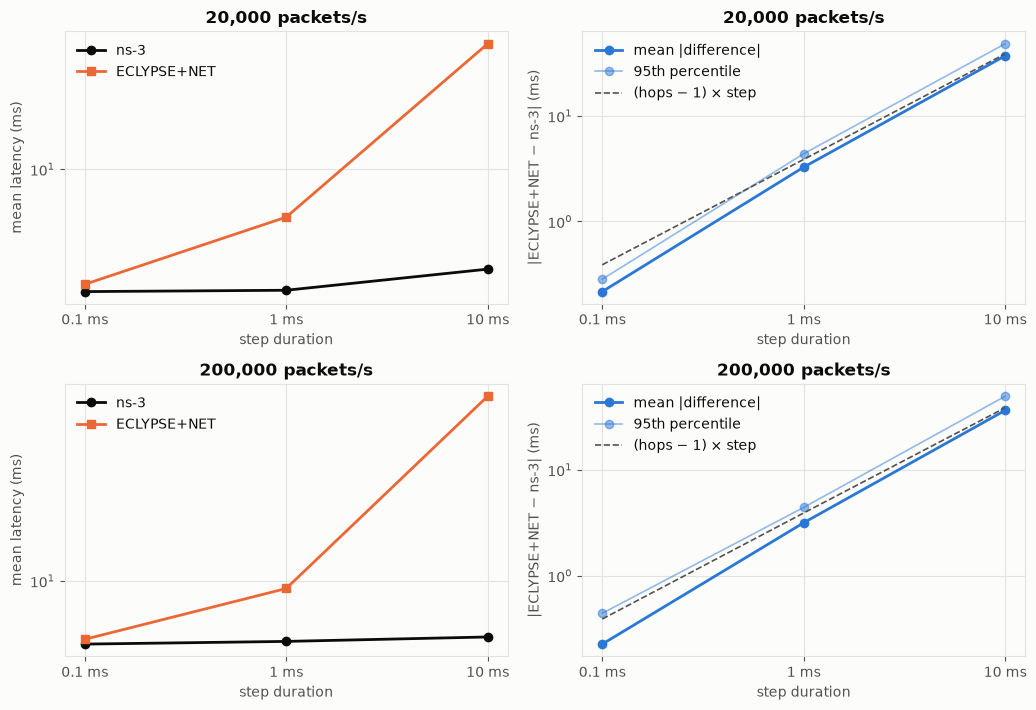

                               eclypse_latency_ms_mean  latency_absdiff_mean_ms  latency_diff_mean_ms  ns3_latency_ms_mean
packets_per_s step_duration_s                                                                                             
20000         0.0100                            40.384                   37.095                37.095                3.289
              0.0010                             5.866                    3.266                 3.266                2.600
              0.0001                             2.777                    0.216                 0.216                2.562
200000        0.0100                            42.194                   36.389                36.389                6.458
              0.0010                             9.424                    3.157                 3.157                6.239
              0.0001                             6.342                    0.225                 0.215                6.109


In [4]:
fig, axes = plt.subplots(len(LOADS), 2, figsize=(10.5, 3.6 * len(LOADS)), squeeze=False)
for row, load in zip(axes, LOADS):
    d = df[df["packets_per_s"] == load].groupby("step_duration_s")[
        ["eclypse_latency_ms_mean", "ns3_latency_ms_mean", "latency_absdiff_mean_ms",
         "latency_absdiff_p95_ms", "hops_mean"]].mean()
    x = d.index * 1000
    left, right = row
    left.plot(x, d["ns3_latency_ms_mean"], color=NS3_COLOR, marker="o", linewidth=2,
              label="ns-3")
    left.plot(x, d["eclypse_latency_ms_mean"], color="#eb6834", marker="s",
              linewidth=2, label="ECLYPSE+NET")
    left.set_ylabel("mean latency (ms)")
    left.set_yscale("log")
    left.set_title(load_label(load))
    left.legend(loc="upper left")

    right.plot(x, d["latency_absdiff_mean_ms"], color="#2a78d6", marker="o",
               linewidth=2, label="mean |difference|")
    right.plot(x, d["latency_absdiff_p95_ms"], color="#2a78d6", marker="o",
               linewidth=1.2, alpha=0.5, label="95th percentile")
    right.plot(x, (d["hops_mean"] - 1) * x, color=TEXT_MUTED, linestyle="--",
               linewidth=1.2, label="(hops − 1) × step")
    right.set_yscale("log")
    right.set_ylabel("|ECLYPSE+NET − ns-3| (ms)")
    right.set_title(load_label(load))
    right.legend(loc="upper left")
    for ax in row:
        ax.set_xscale("log")
        ax.set_xticks([s * 1000 for s in STEPS], [step_label(s) for s in STEPS])
        ax.minorticks_off()
        ax.set_xlabel("step duration")
fig.tight_layout()
plt.show()

table = df.pivot_table(index=["packets_per_s", "step_duration_s"],
                       values=["ns3_latency_ms_mean", "eclypse_latency_ms_mean",
                               "latency_diff_mean_ms", "latency_absdiff_mean_ms"],
                       aggfunc="mean").sort_index(ascending=[True, False])
print(table.round(3).to_string())

## 3. Packet by packet

Distribution of the end-to-end latency in one scenario: the largest network of the
chosen topology, at the highest load, for every step duration. ns-3 is shown for the
packets of the shortest step, whose sending times are the closest to a continuous
flow.

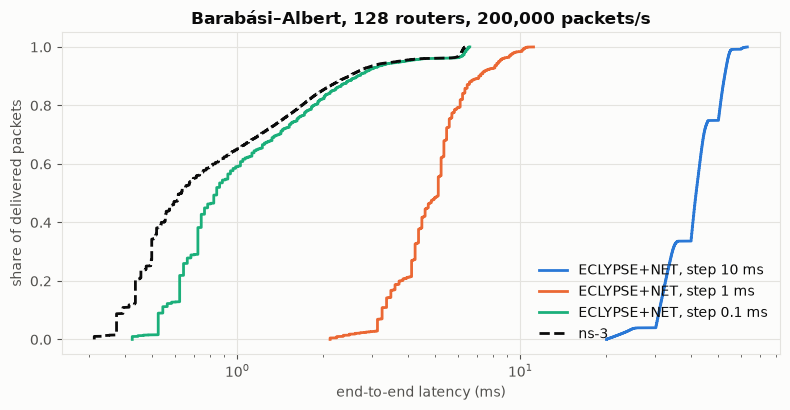

In [5]:
TOPOLOGY = "scale_free" if "scale_free" in TOPOLOGIES else next(iter(TOPOLOGIES))
ROUTERS, LOAD, SEED = max(SIZES), max(LOADS), sorted(df["seed"].unique())[0]


def comparison(dt):
    name = f"{TOPOLOGY}_{ROUTERS}_{dt:g}_{LOAD}_{SEED}"
    return pd.read_csv(RESULTS / "trials" / name / "comparison.csv")


def cdf(ax, values, **style):
    values = np.sort(values.dropna().to_numpy())
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), **style)


fig, ax = plt.subplots(figsize=(8, 4.2))
for dt in STEPS:
    cdf(ax, comparison(dt)["eclypse_latency_ms"], color=STEP_COLORS[dt], linewidth=2,
        label=f"ECLYPSE+NET, step {step_label(dt)}")
cdf(ax, comparison(min(STEPS))["ns3_latency_ms"], color=NS3_COLOR, linewidth=2,
    linestyle="--", label="ns-3")
ax.set_xscale("log")
ax.set_xlabel("end-to-end latency (ms)")
ax.set_ylabel("share of delivered packets")
ax.set_title(f"{TOPOLOGIES[TOPOLOGY]}, {ROUTERS} routers, {load_label(LOAD)}")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 4. Execution time

Wall-clock time of the simulation against the number of routers: `sim.start()` to
`sim.wait()` for ECLYPSE+NET, `Simulator::Run()` for ns-3, on log-log axes. Both
simulate the same 0.2 s of network time. ECLYPSE+NET runs one step every step
duration, so its time grows as the step gets shorter; ns-3 runs one event per packet
and per hop, whatever the step.

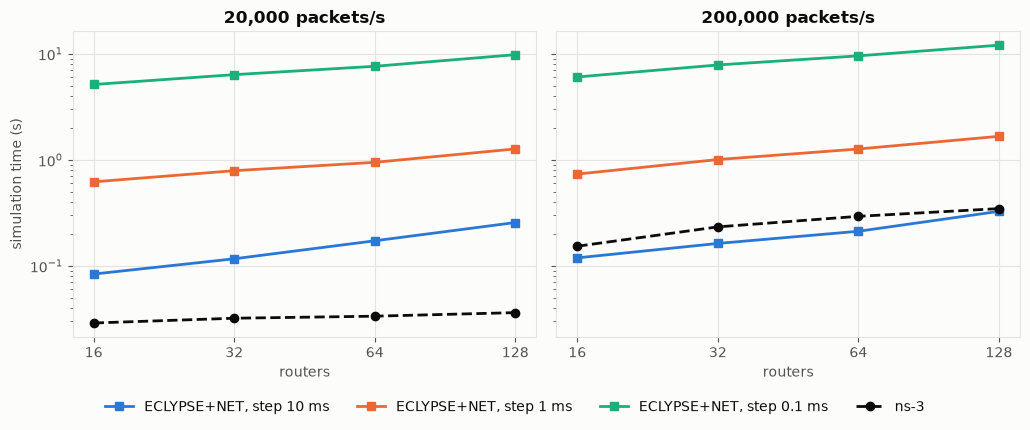

                       ECLYPSE+NET 0.1 ms  ECLYPSE+NET 1 ms  ECLYPSE+NET 10 ms   ns-3
packets_per_s routers                                                                
20000         16                    5.129             0.620              0.084  0.029
              32                    6.350             0.789              0.117  0.032
              64                    7.615             0.946              0.172  0.034
              128                   9.795             1.267              0.256  0.036
200000        16                    6.039             0.734              0.119  0.153
              32                    7.839             1.006              0.163  0.233
              64                    9.551             1.264              0.212  0.293
              128                  12.045             1.665              0.326  0.347


In [6]:
fig, axes = plt.subplots(1, len(LOADS), figsize=(5.2 * len(LOADS), 4), sharey=True,
                         squeeze=False)
for ax, load in zip(axes[0], LOADS):
    d = df[df["packets_per_s"] == load]
    for dt in STEPS:
        s = d[d["step_duration_s"] == dt].groupby("routers")
        ax.plot(SIZES, s["eclypse_sim_time_s"].mean().reindex(SIZES),
                color=STEP_COLORS[dt], marker="s", linewidth=2,
                label=f"ECLYPSE+NET, step {step_label(dt)}")
    ns3 = d[d["step_duration_s"] == min(STEPS)].groupby("routers")["ns3_run_time_s"]
    ax.plot(SIZES, ns3.mean().reindex(SIZES), color=NS3_COLOR, marker="o",
            linestyle="--", linewidth=2, label="ns-3")
    ax.set_xscale("log", base=2)
    ax.set_xticks(SIZES, [str(s) for s in SIZES])
    ax.minorticks_off()
    ax.set_yscale("log")
    ax.set_xlabel("routers")
    ax.set_title(load_label(load))
axes[0, 0].set_ylabel("simulation time (s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels),
           bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()

times = df.pivot_table(index=["packets_per_s", "routers"], columns="step_duration_s",
                       values="eclypse_sim_time_s", aggfunc="mean")
times.columns = [f"ECLYPSE+NET {step_label(c)}" for c in times.columns]
times["ns-3"] = (df[df["step_duration_s"] == min(STEPS)]
                 .groupby(["packets_per_s", "routers"])["ns3_run_time_s"].mean())
print(times.round(3).to_string())